# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('SAML-D.csv')

# Exploratory Data Analysis

In [3]:
df.head()

,Time,Date,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Laundering_type
0,10:35:19,07-10-2022,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,10:35:20,07-10-2022,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,10:35:20,07-10-2022,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,10:35:21,07-10-2022,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,10:35:21,07-10-2022,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [4]:

# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Display the column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 4. Count normal and laundering-labelled transactions
print("\nLaundering label counts:")
print(df["Is_laundering"].value_counts())


Dataset shape: (1048575, 12)

Column names:
['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount', 'Payment_currency', 'Received_currency', 'Sender_bank_location', 'Receiver_bank_location', 'Payment_type', 'Is_laundering', 'Laundering_type']

Missing values in each column:
Time                      0
Date                      0
Sender_account            0
Receiver_account          0
Amount                    0
Payment_currency          0
Received_currency         0
Sender_bank_location      0
Receiver_bank_location    0
Payment_type              0
Is_laundering             0
Laundering_type           0
dtype: int64

Laundering label counts:
Is_laundering
0    1047619
1        956
Name: count, dtype: int64


In [5]:
 #understanding transaction amount

print(df['Amount'].describe())

count    1.048575e+06
mean     8.707645e+03
std      2.444582e+04
min      5.190000e+00
25%      2.114535e+03
50%      6.104870e+03
75%      1.034893e+04
max      6.213932e+06
Name: Amount, dtype: float64


In [6]:
 #Comparing normal and laundering-labelled transactions

df.groupby("Is_laundering")['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Is_laundering,,,,,,,,
0,1047619.0,8682.218377,22265.084861,5.19,2113.7700,6105.81,10349.845,999946.47
1,956.0,36571.563239,334010.895411,24.77,2821.4875,5133.36,8867.410,6213931.56


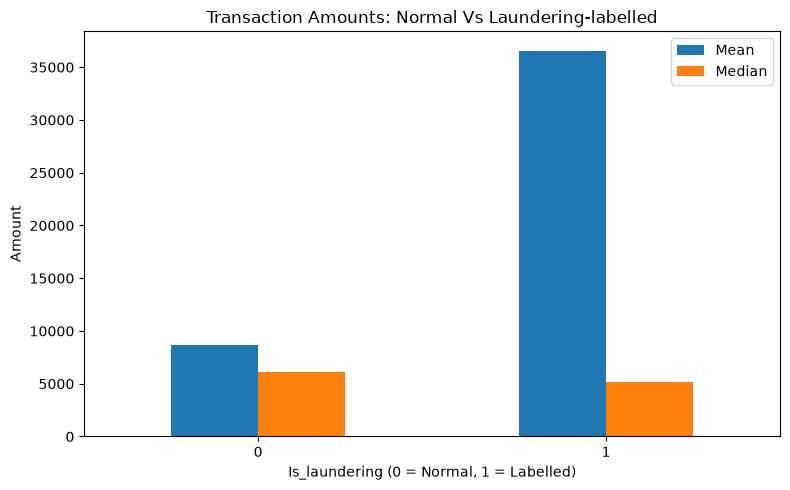

In [7]:
 #Visualizing the difference

summary = df.groupby("Is_laundering")['Amount'].agg(["mean", "median"])

summary.plot(kind = "bar", figsize = (8,5))

plt.title("Transaction Amounts: Normal Vs Laundering-labelled")
plt.xlabel("Is_laundering (0 = Normal, 1 = Labelled)")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend(["Mean", "Median"])
plt.tight_layout()
plt.show()